# 🩺 Sirroz bemorlari omon qolish prognozini aniqlash
### Cirrhosis Patient Survival Prediction

**Vazifa:** `test.csv` dagi har bir bemor uchun 3 ta holatning **ehtimolligini** bashorat qilish:

| Klass | Ma'nosi |
|---|---|
| `C` | Senzuralangan — bemor `N_Days` kunida tirik |
| `CL` | Jigar transplantatsiyasi tufayli senzuralangan — bemor tirik |
| `D` | Bemor `N_Days` kunida vafot etgan |



## 1. Sozlash

In [2]:
import importlib.util
import subprocess
import sys

REQUIRED = {"lightgbm": "lightgbm", "xgboost": "xgboost", "sklearn": "scikit-learn", "seaborn": "seaborn"}

missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("O'rnatilmoqda:", ", ".join(missing), "...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Tayyor ")
else:
    print("Barcha kutubxonalar o'rnatilgan ")

Barcha kutubxonalar o'rnatilgan 


In [3]:
import os
import glob
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

print("Kutubxonalar yuklandi ")

Kutubxonalar yuklandi 


In [4]:
SEED = 42
N_FOLDS = 5
TARGET = "Status"
CLASSES = ["C", "CL", "D"]
OUTPUT_PATH = "submission.csv"


def find_file(name):
    dirs = [".", "./data", "/content", *glob.glob("/kaggle/input/*"), *glob.glob("/kaggle/input/*/*")]
    for d in dirs:
        path = os.path.join(d, name)
        if os.path.exists(path):
            return path
    return None


TRAIN_PATH = find_file("train.csv")
TEST_PATH = find_file("test.csv")
SUB_PATH = find_file("sample_submission.csv")
ORIGINAL_PATH = find_file("cirrhosis.csv")

if None in (TRAIN_PATH, TEST_PATH, SUB_PATH):
    raise FileNotFoundError(
        "train.csv / test.csv / sample_submission.csv topilmadi. "
    )

USE_ORIGINAL = ORIGINAL_PATH is not None
print(f"train.csv          -> {TRAIN_PATH}")
print(f"test.csv           -> {TEST_PATH}")
print(f"sample_submission  -> {SUB_PATH}")
print(f"asl dataset        -> {ORIGINAL_PATH or 'topilmadi (ixtiyoriy)'}")

train.csv          -> ./train.csv
test.csv           -> ./test.csv
sample_submission  -> ./sample_submission.csv
asl dataset        -> topilmadi (ixtiyoriy)


## 2. Ma'lumotlarni yuklash

In [5]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_sub = pd.read_csv(SUB_PATH)

print(f"Train: {train.shape[0]:,} qator × {train.shape[1]} ustun")
print(f"Test:  {test.shape[0]:,} qator × {test.shape[1]} ustun")
print(f"Sample submission ustunlari: {list(sample_sub.columns)}")
train.head()

Train: 15,000 qator × 20 ustun
Test:  10,000 qator × 19 ustun
Sample submission ustunlari: ['id', 'Status_C', 'Status_CL', 'Status_D']


,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,2178.0,D-penicillamine,16374.0,F,N,N,N,N,0.5,263.0,3.20,43.0,1110.0,106.95,67.0,430.0,9.6,3.0,C
1,1,2644.0,D-penicillamine,17774.0,F,N,N,N,N,0.8,280.0,3.60,22.0,678.0,62.00,80.0,427.0,13.0,3.0,C
2,2,3069.0,Placebo,17844.0,F,N,N,N,N,1.1,408.0,4.40,54.0,2108.0,142.60,137.0,203.0,10.6,3.0,C
3,3,2216.0,Placebo,19221.0,F,N,Y,Y,N,0.8,252.0,3.70,36.0,843.0,55.80,56.0,336.0,9.6,4.0,C
4,4,2256.0,Placebo,21600.0,F,N,N,N,N,4.7,348.0,3.06,464.0,961.0,120.90,146.0,298.0,11.0,2.0,D


**Ustunlar ma'nosi**

| Ustun | Tavsif |
|---|---|
| `N_Days` | Ro'yxatga olingandan keyin o'tgan kunlar |
| `Drug` | Dori turi (D-penicillamine yoki Placebo) |
| `Age` | Yosh (**kunlarda**) |
| `Sex` | Jinsi |
| `Ascites`, `Hepatomegaly`, `Spiders` | Klinik belgilar bor-yo'qligi (Y/N) |
| `Edema` | Shish: N — yo'q, S — bor (davolash bilan ketgan), Y — davolashga qaramay bor |
| `Bilirubin`, `Cholesterol`, `Albumin`, `Copper`, `Alk_Phos`, `SGOT`, `Tryglicerides`, `Platelets`, `Prothrombin` | Qon tahlillari |
| `Stage` | Kasallikning gistologik bosqichi (1–4) |

In [6]:
overview = pd.DataFrame({
    "turi": train.dtypes.astype(str),
    "yo'q_train_%": (train.isna().mean() * 100).round(1),
    "yo'q_test_%": (test.isna().mean() * 100).reindex(train.columns).round(1),
    "unikal": train.nunique(),
})
overview

,turi,yo'q_train_%,yo'q_test_%,unikal
id,int64,0.0,0.0,15000
N_Days,float64,0.0,0.0,553
Drug,object,43.4,44.0,2
Age,float64,0.0,0.0,391
Sex,object,0.0,0.0,2
Ascites,object,43.3,43.9,2
Hepatomegaly,object,43.4,44.0,2
Spiders,object,43.4,44.0,2
Edema,object,0.0,0.0,3
Bilirubin,float64,0.0,0.0,117


## 3. Ma'lumotlarni tahlil qilish (EDA)
### 3.1 Target taqsimoti

Status
C     10053
D      4565
CL      381
Y         1


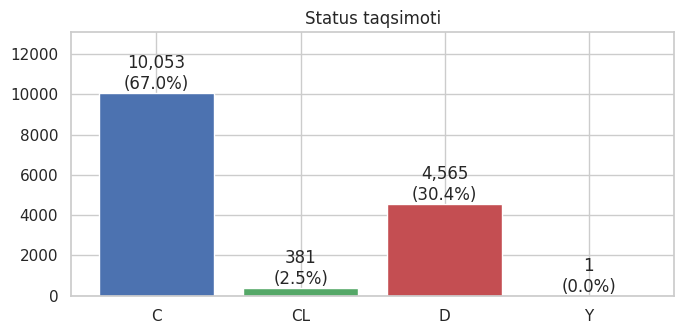

In [7]:
counts = train[TARGET].value_counts()
print(counts.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
order = [c for c in CLASSES + ["Y"] if c in counts.index]
bars = ax.bar(order, counts[order].values, color=["#4C72B0", "#55A868", "#C44E52", "grey"][:len(order)])
for bar, v in zip(bars, counts[order].values):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,}\n({v / len(train):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.3)
ax.set_title("Status taqsimoti")
plt.tight_layout()
plt.show()

- Klasslar **muvozanatsiz**: `CL` atigi ~2.5%. Shuning uchun **stratified** fold'lardan foydalanamiz.
- Train'da bitta `Y` qatori bor — bunday klass submission'da yo'q, bu shunchaki xato yorliq. Uni tozalash bosqichida olib tashlaymiz.

### 3.2 Yo'qolgan qiymatlar

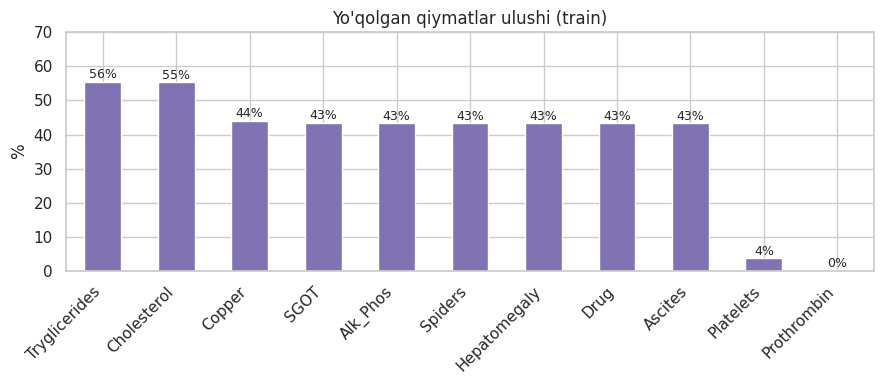

In [8]:
missing_pct = (train.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, ax = plt.subplots(figsize=(9, 4))
missing_pct.plot.bar(ax=ax, color="#8172B3")
for i, v in enumerate(missing_pct):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax.set(title="Yo'qolgan qiymatlar ulushi (train)", ylabel="%", ylim=(0, 70))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

~43% bemorlarda bir nechta ustun **birga** yo'q (`Drug`, `Ascites`, `Hepatomegaly`, `Spiders`, `Copper`, `Alk_Phos`, `SGOT`, ...). Asl tadqiqotda ham bir qism bemorlar klinik sinovda qatnashmagan, shuning uchun ular uchun bu tahlillar yozilmagan.
LightGBM va XGBoost yo'qolgan qiymatlar bilan **o'zi ishlay oladi**, shuning uchun ularni to'ldirish shart emas (faqat Logistic Regression uchun to'ldiramiz).

### 3.3 Sonli belgilar: Status bo'yicha

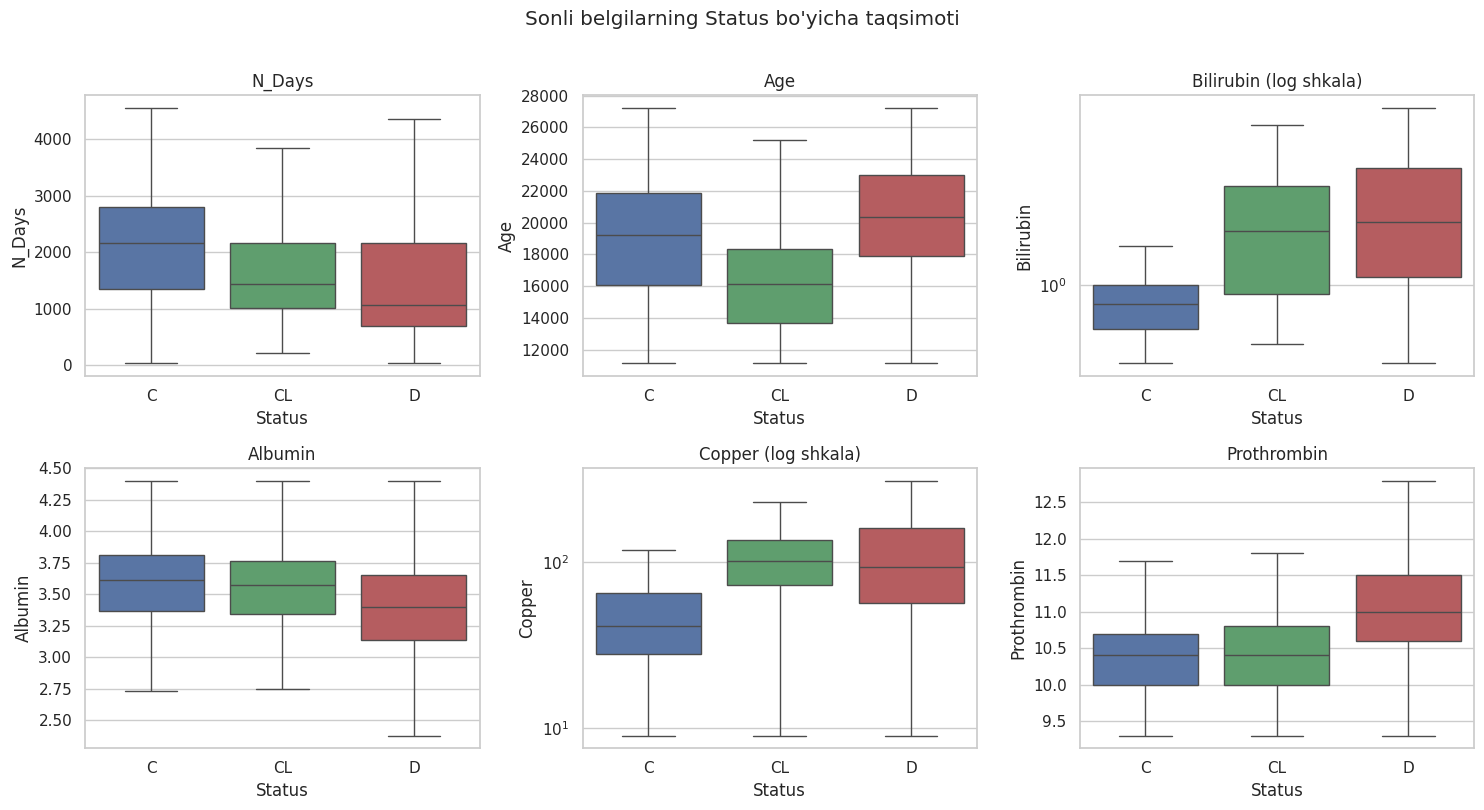

In [9]:
plot_cols = ["N_Days", "Age", "Bilirubin", "Albumin", "Copper", "Prothrombin"]
eda = train[train[TARGET].isin(CLASSES)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_cols):
    data = eda[eda[col].between(eda[col].quantile(0.005), eda[col].quantile(0.995))]
    sns.boxplot(data=data, x=TARGET, y=col, order=CLASSES, ax=ax,
                palette={"C": "#4C72B0", "CL": "#55A868", "D": "#C44E52"}, showfliers=False)
    if col in ("Bilirubin", "Copper"):
        ax.set_yscale("log")
    ax.set_title(col + (" (log shkala)" if col in ("Bilirubin", "Copper") else ""))
plt.suptitle("Sonli belgilarning Status bo'yicha taqsimoti", y=1.01)
plt.tight_layout()
plt.show()

### 3.4 Kategorik belgilar: vafot etish ulushi (`D`)

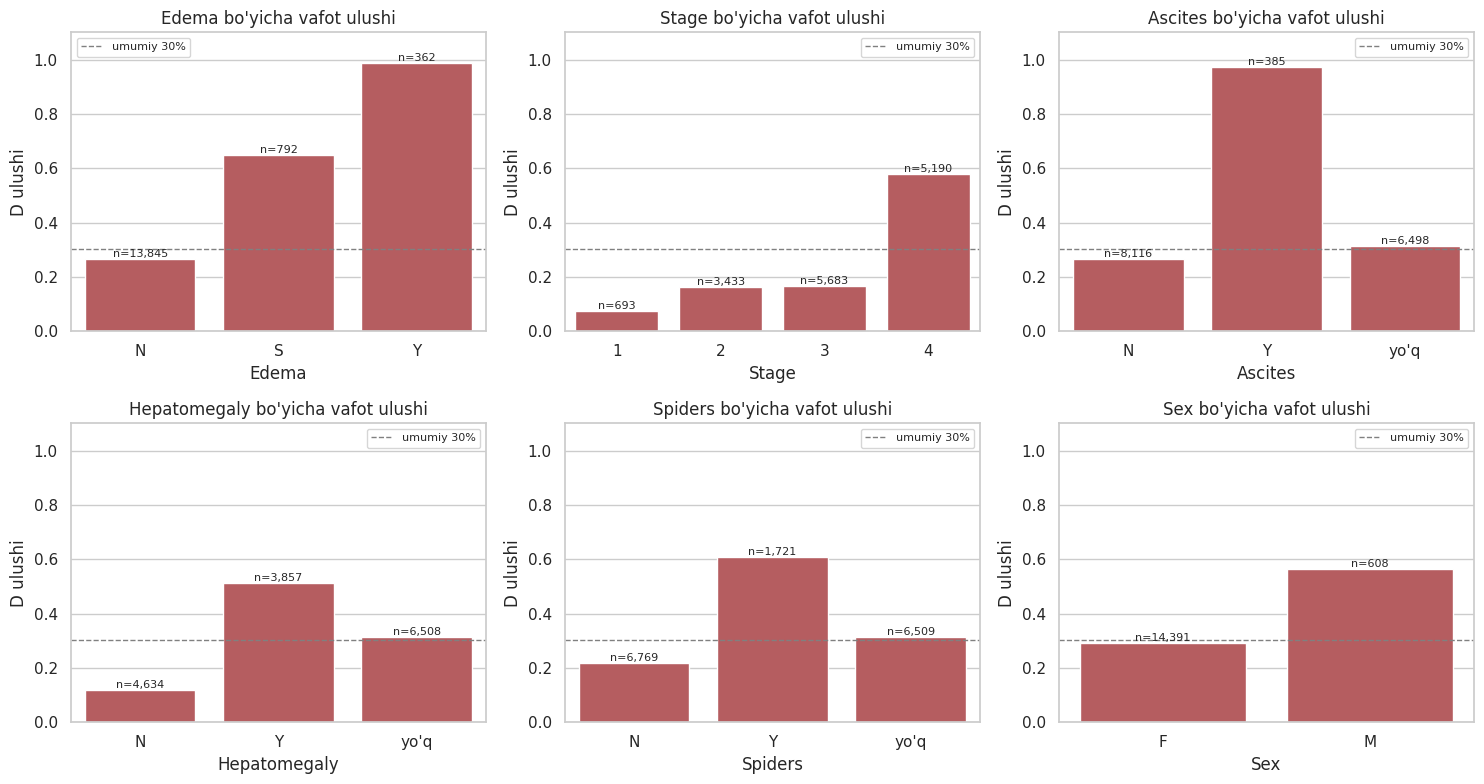

In [10]:
cat_plot = ["Edema", "Stage", "Ascites", "Hepatomegaly", "Spiders", "Sex"]


def group_key(s):
    return s.map(lambda v: "yo'q" if pd.isna(v) else (str(int(v)) if isinstance(v, float) else str(v)))

death_rate = (eda[TARGET] == "D").mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_plot):
    stats = (eda.assign(is_D=eda[TARGET] == "D")
             .groupby(group_key(eda[col]).rename(col))["is_D"].agg(["mean", "size"]).reset_index())
    sns.barplot(data=stats, x=col, y="mean", ax=ax, color="#C44E52")
    ax.axhline(death_rate, ls="--", color="grey", lw=1, label=f"umumiy {death_rate:.0%}")
    for p, n in zip(ax.patches, stats["size"]):
        ax.annotate(f"n={n:,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
    ax.set(ylabel="D ulushi", title=f"{col} bo'yicha vafot ulushi", ylim=(0, 1.1))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**EDA'dan asosiy xulosalar**
- **Bilirubin** — eng kuchli belgilardan biri: bilirubin ≤1 bo'lganlarda vafot ~12%, 5 dan yuqori bo'lganlarda ~83%.
- **Edema** = Y bo'lsa deyarli barcha bemorlar `D` (~99%); **Ascites** = Y bo'lganda ham ~97%.
- **Stage 4** da vafot ~58%, Stage 1 da atigi ~7%.
- `D` bemorlarda **N_Days** qisqaroq, **Copper** va **Prothrombin** yuqoriroq, **Albumin** pastroq.
- `CL` (transplantatsiya) bemorlar odatda **yoshroq**.

## 4. Ma'lumotlarni tozalash
Dataset sun'iy yaratilgan, shuning uchun unda bir nechta **imkonsiz qiymatlar** bor. Masalan, `Age` 129 398 kun (≈354 yosh!) yoki `N_Days` 38 320 kun. Ba'zi qatorlarda esa `N_Days` xato bilan `Age` ga teng bo'lib qolgan.

Har bir belgi uchun **real klinik diapazon** (asl Mayo Clinic ma'lumotlari diapazoniga yaqin) belgilaymiz. Undan tashqaridagi qiymatlarni **NaN** ga aylantiramiz — modellar ularni "noma'lum" deb qabul qiladi, bu xato qiymatni ishlatishdan yaxshiroq.

In [11]:
VALID_RANGES = {
    "N_Days": (41, 4795),          "Age": (9598, 28650),
    "Bilirubin": (0.3, 28),        "Cholesterol": (120, 1775),
    "Albumin": (1.96, 4.64),       "Copper": (4, 588),
    "Alk_Phos": (289, 13862.4),    "SGOT": (26.35, 457.25),
    "Tryglicerides": (33, 598),    "Platelets": (62, 721),
    "Prothrombin": (9, 18),
}

report = pd.DataFrame({
    col: {"min": lo, "max": hi,
          "train_tashqarida": int(((train[col] < lo) | (train[col] > hi)).sum()),
          "test_tashqarida": int(((test[col] < lo) | (test[col] > hi)).sum())}
    for col, (lo, hi) in VALID_RANGES.items()
}).T
print(f"Status = 'Y' qatorlar: {(train[TARGET] == 'Y').sum()}")
report

Status = 'Y' qatorlar: 1


,min,max,train_tashqarida,test_tashqarida
N_Days,41.00,4795.00,30.0,24.0
Age,9598.00,28650.00,18.0,9.0
Bilirubin,0.30,28.00,1.0,1.0
Cholesterol,120.00,1775.00,1.0,0.0
Albumin,1.96,4.64,2.0,1.0
Copper,4.00,588.00,3.0,0.0
Alk_Phos,289.00,13862.40,2.0,3.0
SGOT,26.35,457.25,7.0,6.0
Tryglicerides,33.00,598.00,2.0,0.0
Platelets,62.00,721.00,3.0,5.0


In [12]:
def clean(df):
    df = df.copy()
    for col, (lo, hi) in VALID_RANGES.items():
        df.loc[(df[col] < lo) | (df[col] > hi), col] = np.nan
    return df


train_clean = clean(train[train[TARGET].isin(CLASSES)]).reset_index(drop=True)
test_clean = clean(test)

print(f"Tozalashdan keyin train: {len(train_clean):,} qator")
print(f"NaN ga aylantirilgan qiymatlar (train): {int(report['train_tashqarida'].sum())}")

Tozalashdan keyin train: 14,999 qator
NaN ga aylantirilgan qiymatlar (train): 69


## 5. Belgilarni tayyorlash
- **Sonli belgilar** o'zgarishsiz ishlatiladi (daraxt modellari uchun masshtablash shart emas).
- **Kategorik belgilar** (`Drug`, `Sex`, `Ascites`, ...) — `category` turiga o'tkaziladi; LightGBM va XGBoost ularni o'zi qayta ishlaydi.

> Qo'shimcha belgilar ham sinab ko'rildi (Mayo risk score, ALBI, tashxis qo'yilgandagi yosh, yo'qolgan qiymatlar soni). Ular CV log loss'ni **yaxshilamadi** (aksincha yomonlashtirdi), shuning uchun belgilar to'plamini oddiy qoldiramiz.

In [13]:
NUM_FEATURES = ["N_Days", "Age", "Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos",
                "SGOT", "Tryglicerides", "Platelets", "Prothrombin", "Stage"]
CAT_FEATURES = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema"]
FEATURES = NUM_FEATURES + CAT_FEATURES

if USE_ORIGINAL:
    original = pd.read_csv(ORIGINAL_PATH)
    original = clean(original[original[TARGET].isin(CLASSES)]).reset_index(drop=True)
    print(f"Asl datasetdan {len(original):,} ta qo'shimcha qator qo'shildi")
else:
    original = pd.DataFrame(columns=FEATURES + [TARGET])

for col in CAT_FEATURES:
    cats = sorted(pd.concat([train_clean[col], test_clean[col], original[col]]).dropna().astype(str).unique())
    for df in (train_clean, test_clean, original):
        df[col] = pd.Categorical(df[col].astype("string"), categories=cats)

label_map = {c: i for i, c in enumerate(CLASSES)}
X = train_clean[FEATURES]
y = train_clean[TARGET].map(label_map).values
X_test = test_clean[FEATURES].reset_index(drop=True)
X_orig = original[FEATURES].reset_index(drop=True)
y_orig = original[TARGET].map(label_map).values.astype(int)

for df in (X, X_test, X_orig):
    df[NUM_FEATURES] = df[NUM_FEATURES].astype(float)

print(f"X: {X.shape}, X_test: {X_test.shape}, X_orig: {X_orig.shape}")
X.head()

X: (14999, 18), X_test: (10000, 18), X_orig: (0, 18)


,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Drug,Sex,Ascites,Hepatomegaly,Spiders,Edema
0,2178.0,16374.0,0.5,263.0,3.20,43.0,1110.0,106.95,67.0,430.0,9.6,3.0,D-penicillamine,F,N,N,N,N
1,2644.0,17774.0,0.8,280.0,3.60,22.0,678.0,62.00,80.0,427.0,13.0,3.0,D-penicillamine,F,N,N,N,N
2,3069.0,17844.0,1.1,408.0,4.40,54.0,2108.0,142.60,137.0,203.0,10.6,3.0,Placebo,F,N,N,N,N
3,2216.0,19221.0,0.8,252.0,3.70,36.0,843.0,55.80,56.0,336.0,9.6,4.0,Placebo,F,N,Y,Y,N
4,2256.0,21600.0,4.7,348.0,3.06,464.0,961.0,120.90,146.0,298.0,11.0,2.0,Placebo,F,N,N,N,N


## 6. Cross-validation
**Stratified 5-fold CV**: train 5 bo'lakka bo'linadi, har bir model 5 marta o'qitiladi va har safar o'zi ko'rmagan bo'lakda tekshiriladi.

Natijada:
- **OOF (out-of-fold) bashoratlar** — har bir train qatori uchun "halol" bashorat → ishonchli log loss bahosi va blending uchun ma'lumot.
- **Test bashoratlari** — 5 ta fold modelining o'rtachasi (bitta modeldan barqarorroq).

In [14]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results = {}

prior = np.bincount(y) / len(y)
prior_loss = log_loss(y, np.tile(prior, (len(y), 1)))
print(f"Oddiy baseline (klass ulushlari {dict(zip(CLASSES, prior.round(3).tolist()))}): log loss = {prior_loss:.5f}")


def run_cv(name, fit_predict, features=FEATURES):
    oof = np.zeros((len(X), len(CLASSES)))
    test_pred = np.zeros((len(X_test), len(CLASSES)))
    fold_scores, models = [], []
    start = time.time()

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
        X_tr, y_tr = X.loc[tr_idx, features], y[tr_idx]
        X_va, y_va = X.loc[va_idx, features], y[va_idx]
        if USE_ORIGINAL:
            X_tr = pd.concat([X_tr, X_orig[features]], ignore_index=True)
            y_tr = np.concatenate([y_tr, y_orig])

        model, va_pred, te_pred = fit_predict(X_tr, y_tr, X_va, y_va, X_test[features])
        oof[va_idx] = va_pred
        test_pred += te_pred / N_FOLDS
        fold_scores.append(log_loss(y_va, va_pred))
        models.append(model)
        print(f"  Fold {fold}: log loss = {fold_scores[-1]:.5f}")

    score = log_loss(y, oof)
    elapsed = time.time() - start
    print(f"▶ {name}: CV log loss = {score:.5f} (± {np.std(fold_scores):.5f})  |  {elapsed:.0f} s")
    results[name] = dict(oof=oof, test=test_pred, score=score, std=np.std(fold_scores),
                         time=elapsed, models=models, features=features)

Oddiy baseline (klass ulushlari {'C': 0.67, 'CL': 0.025, 'D': 0.304}): log loss = 0.72352


## 7. Modellar
### 7.1 Baseline — Logistic Regression
Oddiy chiziqli model. Yo'qolgan qiymatlarni median va eng ko'p uchraydigan qiymat bilan to'ldiramiz, sonli belgilarni `log` qilib masshtablaymiz.

In [15]:
def fit_logreg(X_tr, y_tr, X_va, y_va, X_te):
    to_obj = lambda d: d.assign(**{c: d[c].astype(object).where(d[c].notna(), np.nan) for c in CAT_FEATURES})
    num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
    preprocess = ColumnTransformer([("num", num_pipe, NUM_FEATURES), ("cat", cat_pipe, CAT_FEATURES)])
    model = make_pipeline(preprocess, LogisticRegression(max_iter=2000, C=0.5))
    log_num = lambda d: to_obj(d).assign(**{c: np.log1p(d[c]) for c in NUM_FEATURES})
    model.fit(log_num(X_tr), y_tr)
    return model, model.predict_proba(log_num(X_va)), model.predict_proba(log_num(X_te))


run_cv("Logistic Regression", fit_logreg)

  Fold 1: log loss = 0.45484
  Fold 2: log loss = 0.42277
  Fold 3: log loss = 0.44625
  Fold 4: log loss = 0.44123
  Fold 5: log loss = 0.44066
▶ Logistic Regression: CV log loss = 0.44115 (± 0.01050)  |  8 s


### 7.2 LightGBM
Kichik learning rate + **early stopping**: validatsiya log loss 200 raund davomida yaxshilanmasa, o'qitish to'xtaydi.

In [16]:
LGB_PARAMS = dict(
    objective="multiclass", n_estimators=5000, learning_rate=0.02,
    num_leaves=15, max_depth=4, min_child_samples=40, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.3, reg_lambda=1.0, reg_alpha=0.1,
    random_state=SEED, verbose=-1,
)


def fit_lgbm(X_tr, y_tr, X_va, y_va, X_te):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(200, verbose=False)])
    return model, model.predict_proba(X_va), model.predict_proba(X_te)


run_cv("LightGBM", fit_lgbm)

  Fold 1: log loss = 0.37899
  Fold 2: log loss = 0.35190
  Fold 3: log loss = 0.37293
  Fold 4: log loss = 0.36536
  Fold 5: log loss = 0.35995
▶ LightGBM: CV log loss = 0.36582 (± 0.00951)  |  67 s


### 7.3 XGBoost

In [17]:
XGB_PARAMS = dict(
    objective="multi:softprob", n_estimators=5000, learning_rate=0.02,
    max_depth=4, min_child_weight=3, subsample=0.8, colsample_bytree=0.3, reg_lambda=1.0,
    tree_method="hist", enable_categorical=True,
    eval_metric="mlogloss", early_stopping_rounds=200, random_state=SEED,
)


def fit_xgb(X_tr, y_tr, X_va, y_va, X_te):
    model = xgb.XGBClassifier(**XGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return model, model.predict_proba(X_va), model.predict_proba(X_te)


run_cv("XGBoost", fit_xgb)

  Fold 1: log loss = 0.37954
  Fold 2: log loss = 0.35289
  Fold 3: log loss = 0.37080
  Fold 4: log loss = 0.36642
  Fold 5: log loss = 0.36023
▶ XGBoost: CV log loss = 0.36598 (± 0.00907)  |  101 s


> **CatBoost haqida:** CatBoost ham sinab ko'rildi, lekin bu datasetda u LightGBM va XGBoost'dan **yomonroq** (CV log loss ≈ 0.381) va ~5 baravar **sekinroq** ishladi, blendingga ham deyarli hissa qo'shmadi. Shuning uchun notebookni tez va sodda saqlash uchun uni kiritmadik.

## 8. Modellarni solishtirish

In [18]:
leaderboard = (
    pd.DataFrame({name: {"CV log loss": r["score"], "Fold std": r["std"], "Vaqt (s)": r["time"]}
                  for name, r in results.items()})
    .T.sort_values("CV log loss")
)
leaderboard.loc["Oddiy baseline (klass ulushlari)"] = [prior_loss, 0, 0]
leaderboard.round({"CV log loss": 5, "Fold std": 5, "Vaqt (s)": 1})

,CV log loss,Fold std,Vaqt (s)
LightGBM,0.36582,0.00951,66.7
XGBoost,0.36598,0.00907,100.6
Logistic Regression,0.44115,0.01050,8.4
Oddiy baseline (klass ulushlari),0.72352,0.00000,0.0


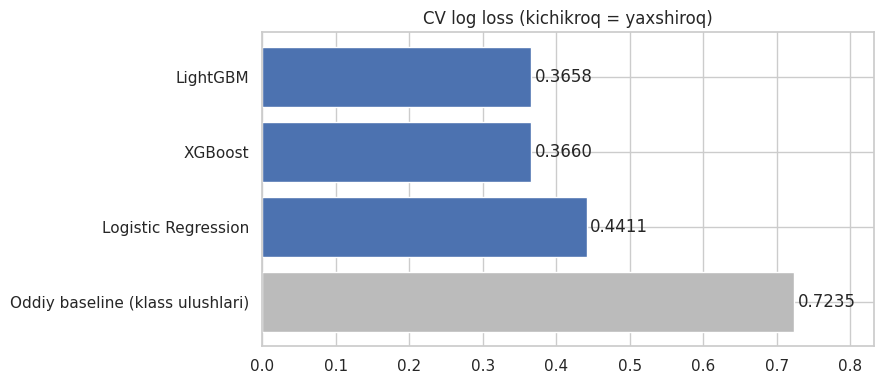

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
lb = leaderboard["CV log loss"].sort_values(ascending=False)
colors = ["#BBBBBB" if "baseline" in n.lower() else "#4C72B0" for n in lb.index]
ax.barh(lb.index, lb.values, color=colors)
for i, v in enumerate(lb.values):
    ax.text(v + 0.005, i, f"{v:.4f}", va="center")
ax.set(title="CV log loss (kichikroq = yaxshiroq)", xlim=(0, lb.max() * 1.15))
plt.tight_layout()
plt.show()

## 9. Modellarni birlashtirish (blending)
Turli modellar turli xatolar qiladi, shuning uchun ularning ehtimolliklarini **og'irlikli o'rtacha** qilish ko'pincha har biridan yaxshiroq natija beradi.
LightGBM va XGBoost uchun eng yaxshi og'irlikni **OOF bashoratlar** ustida qidiramiz.

Eng yaxshi og'irliklar: LightGBM = 0.55, XGBoost = 0.45
Blend OOF log loss:     0.36537
Eng yaxshi yakka model: LightGBM (0.36582)
Yaxshilanish:           +0.00045


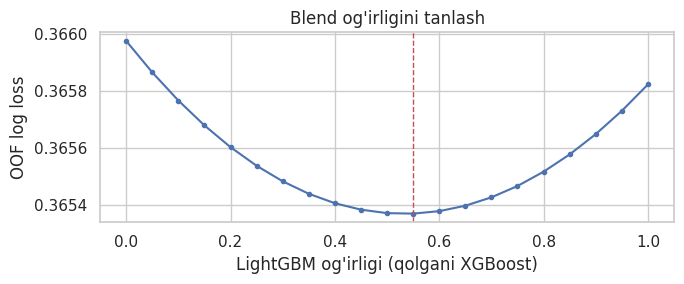

In [20]:
BLEND_MODELS = ["LightGBM", "XGBoost"]
oof_lgb, oof_xgb = (results[m]["oof"] for m in BLEND_MODELS)
test_lgb, test_xgb = (results[m]["test"] for m in BLEND_MODELS)


def normalize(p):
    return p / p.sum(axis=1, keepdims=True)


weights = np.round(np.arange(0, 1.0001, 0.05), 2)
losses = [log_loss(y, normalize(w * oof_lgb + (1 - w) * oof_xgb)) for w in weights]
best_w = float(weights[int(np.argmin(losses))])
best_loss = min(losses)

best_single = leaderboard.index[0]
print(f"Eng yaxshi og'irliklar: LightGBM = {best_w:.2f}, XGBoost = {1 - best_w:.2f}")
print(f"Blend OOF log loss:     {best_loss:.5f}")
print(f"Eng yaxshi yakka model: {best_single} ({results[best_single]['score']:.5f})")
print(f"Yaxshilanish:           {results[best_single]['score'] - best_loss:+.5f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(weights, losses, marker="o", ms=3)
ax.axvline(best_w, color="#C44E52", ls="--", lw=1)
ax.set(xlabel="LightGBM og'irligi (qolgani XGBoost)", ylabel="OOF log loss", title="Blend og'irligini tanlash")
plt.tight_layout()
plt.show()

final_oof = normalize(best_w * oof_lgb + (1 - best_w) * oof_xgb)
final_test = normalize(best_w * test_lgb + (1 - best_w) * test_xgb)

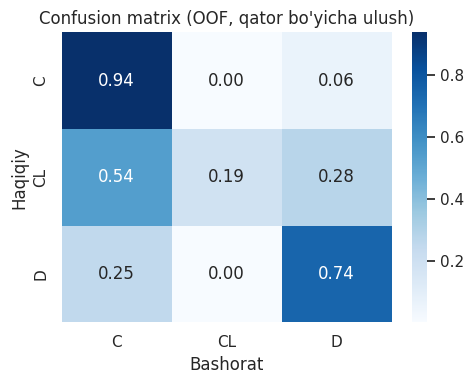

Eslatma: CL klassi juda kam (~2.5%), shuning uchun model uni kamdan-kam 'eng ehtimolli' deb tanlaydi —
log loss uchun esa unga to'g'ri kichik ehtimollik berish muhim.


In [21]:
cm = confusion_matrix(y, final_oof.argmax(axis=1), normalize="true")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(xlabel="Bashorat", ylabel="Haqiqiy", title="Confusion matrix (OOF, qator bo'yicha ulush)")
plt.tight_layout()
plt.show()
print("Eslatma: CL klassi juda kam (~2.5%), shuning uchun model uni kamdan-kam 'eng ehtimolli' deb tanlaydi —")
print("log loss uchun esa unga to'g'ri kichik ehtimollik berish muhim.")

## 10. Belgilar muhimligi
Model qaysi belgilarga ko'proq tayanadi? (5 ta fold modeli bo'yicha o'rtacha.)

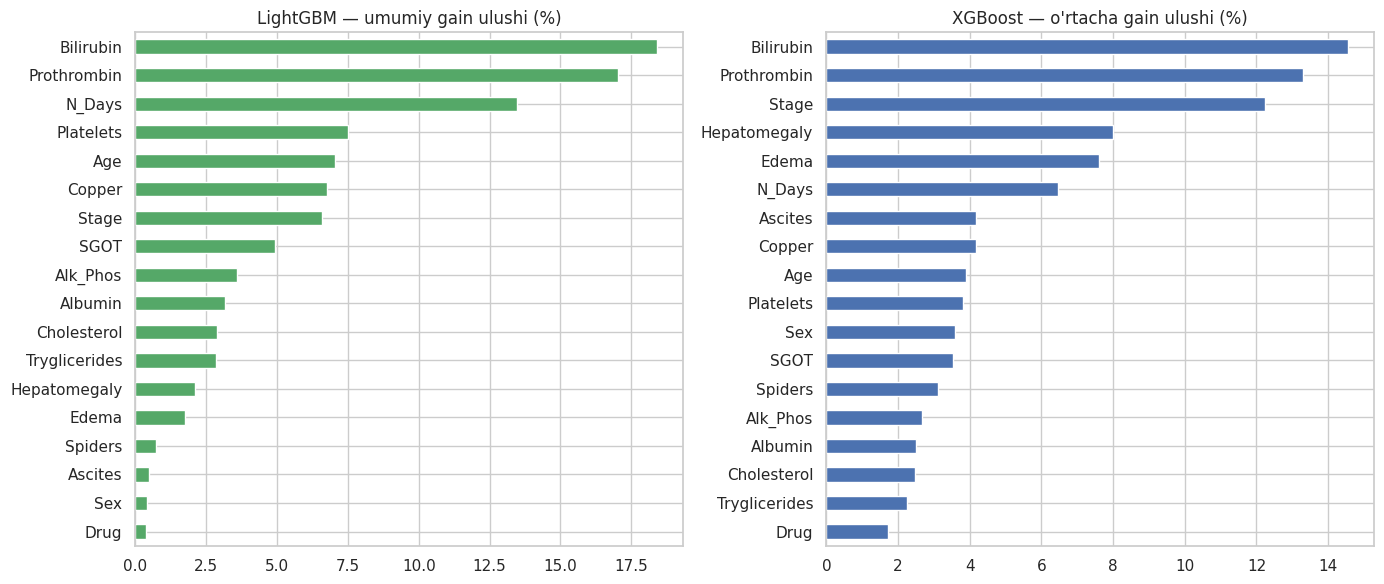

In [22]:
lg = results["LightGBM"]
lgb_imp = pd.Series(np.mean([m.booster_.feature_importance("gain") for m in lg["models"]], axis=0), index=lg["features"])
lgb_imp = (lgb_imp / lgb_imp.sum() * 100).sort_values()

xg = results["XGBoost"]
xgb_imp = pd.DataFrame([m.get_booster().get_score(importance_type="gain") for m in xg["models"]]).mean()
xgb_imp = xgb_imp.reindex(xg["features"]).fillna(0)
xgb_imp = (xgb_imp / xgb_imp.sum() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lgb_imp.plot.barh(ax=axes[0], color="#55A868", title="LightGBM — umumiy gain ulushi (%)")
xgb_imp.plot.barh(ax=axes[1], color="#4C72B0", title="XGBoost — o'rtacha gain ulushi (%)")
plt.tight_layout()
plt.show()

Ikkala modelda ham **Bilirubin** va **Prothrombin** eng muhim belgilar; undan keyin **N_Days**, **Stage**, **Age** va **Copper** keladi. Bu EDA natijalariga mos keladi. `Drug` (dori turi) deyarli ta'sir qilmaydi.

## 11. Submission fayli
Format: `id,Status_C,Status_CL,Status_D` — har bir test `id` si uchun 3 ta ehtimollik (yig'indisi 1 ga teng).

In [23]:
pred = pd.DataFrame(final_test, columns=[f"Status_{c}" for c in CLASSES])
pred.insert(0, "id", test["id"].values)
submission = sample_sub[["id"]].merge(pred, on="id", how="left")

prob_cols = [f"Status_{c}" for c in CLASSES]
assert list(submission.columns) == list(sample_sub.columns), "Ustunlar noto'g'ri"
assert len(submission) == len(sample_sub), "Qatorlar soni mos emas"
assert submission[prob_cols].notna().all().all(), "Bo'sh bashoratlar bor"
assert np.allclose(submission[prob_cols].sum(axis=1), 1, atol=1e-6), "Ehtimolliklar yig'indisi 1 emas"
assert submission[prob_cols].ge(0).all().all(), "Manfiy ehtimollik"

submission.to_csv(OUTPUT_PATH, index=False)
print(f" {OUTPUT_PATH} saqlandi: {len(submission):,} qator")
print("O'rtacha bashorat qilingan ulushlar:", submission[prob_cols].mean().round(3).to_dict())
print("Train'dagi haqiqiy ulushlar:        ", dict(zip(prob_cols, prior.round(3).tolist())))
submission.head(10)

 submission.csv saqlandi: 10,000 qator
O'rtacha bashorat qilingan ulushlar: {'Status_C': 0.672, 'Status_CL': 0.021, 'Status_D': 0.307}
Train'dagi haqiqiy ulushlar:         {'Status_C': 0.67, 'Status_CL': 0.025, 'Status_D': 0.304}


,id,Status_C,Status_CL,Status_D
0,15000,0.353628,0.002774,0.643598
1,15001,0.871952,0.011631,0.116416
2,15002,0.729067,0.007930,0.263003
3,15003,0.985627,0.000576,0.013797
4,15004,0.236192,0.129568,0.634241
5,15005,0.860258,0.008012,0.131730
6,15006,0.191704,0.005247,0.803049
7,15007,0.013761,0.000923,0.985316
8,15008,0.622623,0.005244,0.372133
9,15009,0.962763,0.006773,0.030465


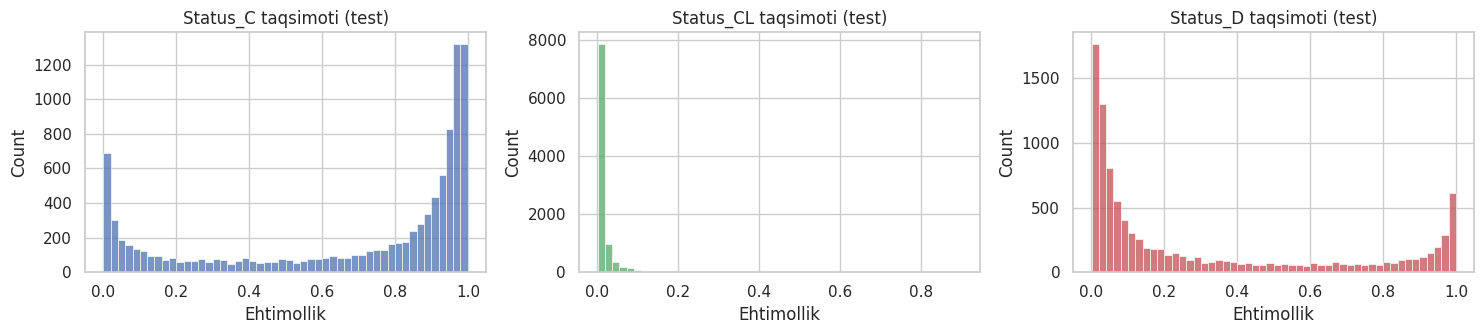

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, color in zip(axes, prob_cols, ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(submission[col], bins=50, ax=ax, color=color)
    ax.set(title=f"{col} taqsimoti (test)", xlabel="Ehtimollik")
plt.tight_layout()
plt.show()

## 12. Xulosa
Sirroz bemorlarining holatini (`C`, `CL`, `D`) bashorat qilish uchun LightGBM va XGBoost modellari o'qitildi, ularning birlashmasi eng yaxshi natija berdi (CV log loss ≈ **0.365**, oddiy baseline esa 0.724). Bemor holatiga eng ko'p ta'sir qiladigan belgilar — **Bilirubin**, **Prothrombin**, kuzatuv muddati (**N_Days**) va kasallik bosqichi (**Stage**). Yakuniy ehtimolliklar `submission.csv` fayliga saqlandi.